In [2]:
import os
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler 
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import LabelEncoder

In [3]:
# Path: dataset.ipynb

In [4]:
# from data/results_data/processed we need to combine all the csv files into one
# and then save it as a new csv file

def access_folders(folder_path):
    # Get all the files in the directory
    folder_list = os.listdir(f'{folder_path}/processed')
    return folder_list

def access_files(fold, folder_path):
    # Get all the files in the directory
    if fold == '.DS_Store':
        return []
    file_list = os.listdir(f'{folder_path}processed/{fold}')
    return file_list

def get_data_from_date(fold, file_name, folder_path):
    # Read the file
    data = pd.read_csv(f'{folder_path}/processed/{fold}/{file_name}')
    # Append the data to the dataframe
    return data

def combine_append_df(data, new_df):
    # concat the data to the dataframe
    data = pd.concat([data, new_df], ignore_index=True)
    return data

def save_file(dataset_save, save_path):
    # Save the dataframe as a csv file
    dataset_save.to_csv(save_path, index=False)
    

In [5]:
### Main function
# empty dataframe
def create_dataset(d):
    if not os.path.exists('datasets'):
        os.mkdir('datasets')
    if not os.path.exists('datasets/dataset_' + d):
        os.mkdir('datasets/dataset_' + d)
    path = os.getcwd() + f'/datasets/dataset_{d}/dataset.csv' # '/Users/serkan/Desktop/mod12_research/code'
    # path of source folders
    source_folders = f"graph_results/{d}_data/"

    dataframe = pd.DataFrame()
    folders = access_folders(source_folders)

    for folder_to_use in folders:
        files = access_files(folder_to_use, source_folders)
        for file in files:
            temp_df = get_data_from_date(folder_to_use, file, source_folders)
            dataframe = combine_append_df(dataframe, temp_df)
    dataframe = dataframe.drop(columns=['TimeStamp'])
    save_file(dataframe, path)

    dataframe['Time(sec)'] = dataframe.index*6
    axs = dataframe.plot.line(x='Time(sec)',figsize=(20, 25), subplots=True)
    path = path[:-4] + '.png'
    plt.savefig(path)
    plt.close("all")


In [6]:
# path to save the dataset
f = os.listdir('data')
for i in f:
    if i != '.DS_Store':
        print(i)
        create_dataset(i)


ready
broken1
broken2


In [7]:
df = pd.DataFrame()
source_folder = "graph_results/ready_data/"
folder = access_folders(source_folder)
for folder_to_process in folder:
    ac_files = access_files(folder_to_process, source_folder)
    for ac_file in ac_files:
        t_df = get_data_from_date(folder_to_process, ac_file, source_folder)
        df = combine_append_df(df, t_df)
df = df.drop(columns=['TimeStamp'])
df['Time(sec)'] = df.index*6
# new feature multiply frequency with temperature
df['Frequency_L2_Current_Temperature'] = df['Frequency L2 Current'] / df['Temperature(DegC)']
df['Frequency_L2_Z_Axis_Peak_Acceleration'] = df['Z-Axis Peak Acceleration(G)'] / df['Frequency L2 Current']

label_encoder = LabelEncoder()
df['machine_state'] = label_encoder.fit_transform(df['machine_state'])




In [8]:
# we need to calculate for every frequency how many normal and how many faulty there are only get which have more than 30
count_df = df.groupby('machine_state')['Frequency L2 Current'].value_counts()
count_df = count_df.unstack()
count_df.fillna(0, inplace=True)
count_df = count_df.loc[:, (count_df > 10).all()]
# count_df
print(df.shape)

(26530, 40)


In [9]:
# get equal number of normal and faulty data for each frequency
# get the minimum number of normal and faulty data
# every column is a frequency and every row is a machine state
min_val = count_df.min().reset_index()
min_val = min_val.set_index('Frequency L2 Current')
min_val.columns = ['min']

# get the minimum amounts random data for each frequency
normal_data = pd.DataFrame()
faulty_data = pd.DataFrame()
normal_data_test = pd.DataFrame()
faulty_data_test = pd.DataFrame()

for i in min_val.index:
    t = min_val.loc[i, 'min']
    # get train data balanced
    normal_data = pd.concat([normal_data, df[(df['machine_state'] == 1) & (df['Frequency L2 Current'] == i)].sample(int(t))])
    faulty_data = pd.concat([faulty_data, df[(df['machine_state'] == 0) & (df['Frequency L2 Current'] == i)].sample(int(t))])

normal_data_test = df[(df['machine_state'] == 1)].drop(normal_data.index)
faulty_data_test = df[(df['machine_state'] == 0)].drop(faulty_data.index)

print(normal_data.shape)
print(faulty_data.shape)
print(normal_data_test.shape)
print(faulty_data_test.shape)
train_data = pd.concat([normal_data, faulty_data])
test_data = pd.concat([normal_data_test, faulty_data_test])
train_data.to_csv('models/data/train_data.csv')
test_data.to_csv('models/data/test_data.csv')

(4412, 40)
(4412, 40)
(4284, 40)
(13422, 40)


In [10]:
# standardize data
X = train_data.drop(columns=['machine_state'])
y = train_data['machine_state']
scalar = StandardScaler()
X_scaled = scalar.fit_transform(X)
X

,Z-Axis RMS Velocity(in/sec),Z-Axis RMS Velocity(mm/sec),Temperature(DegF),Temperature(DegC),X-Axis RMS Velocity(in/sec),X-Axis RMS Velocity(mm/sec),Z-Axis Peak Acceleration(G),X-Axis Peak Acceleration(G),Z-Axis Peak Velocity Component Frequency(Hz),X-Axis Peak Velocity Component Frequency(Hz),...,Phase Shift L3(Degrees),Frequency L1 Current(Hz),Frequency L2 Current,Frequency L3 Current(Hz),Frequency L1 Voltage(Hz),15V sense,VIN sense,Time(sec),Frequency_L2_Current_Temperature,Frequency_L2_Z_Axis_Peak_Acceleration
24548,0.0279,0.709,95.53,35.29,0.0410,1.043,0.043,0.053,51.2,51.2,...,-2.73,1.0,0.5,1.5,7.0,14987.0,23560.0,147288,0.014168,0.086000
20806,0.0286,0.726,86.94,30.52,0.0386,0.982,0.047,0.054,51.2,51.2,...,-4.57,1.5,0.5,0.5,6.0,14987.0,23620.0,124836,0.016383,0.094000
24552,0.0281,0.715,95.53,35.29,0.0395,1.005,0.059,0.057,51.2,51.2,...,-4.57,1.5,0.5,1.0,3.0,14942.0,23568.0,147312,0.014168,0.118000
24553,0.0285,0.723,95.64,35.35,0.0386,0.982,0.044,0.055,51.2,51.2,...,-2.73,1.0,0.5,1.5,15.0,14987.0,23590.0,147318,0.014144,0.088000
20804,0.0302,0.769,86.70,30.38,0.0415,1.056,0.360,0.224,51.2,51.2,...,-2.73,1.0,0.5,1.5,7.0,14920.0,23664.0,124824,0.016458,0.720000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23329,0.1349,3.427,85.13,29.52,0.3755,9.538,0.838,1.141,29.2,29.2,...,-82.78,30.0,30.0,30.0,30.0,14913.0,23620.0,139974,1.016260,0.027933
23194,0.1283,3.259,84.89,29.38,0.4319,10.970,0.924,1.029,29.2,29.2,...,-81.88,30.0,30.0,30.0,30.0,14935.0,23657.0,139164,1.021103,0.030800
22793,0.1350,3.429,84.74,29.30,0.4514,11.467,1.064,0.735,29.2,29.2,...,-82.75,30.0,30.0,30.0,30.0,15002.0,23634.0,136758,1.023891,0.035467
23091,0.1181,3.001,84.79,29.33,0.4423,11.235,1.085,1.057,29.2,29.2,...,-82.91,30.0,30.0,30.0,30.0,14928.0,23716.0,138546,1.022844,0.036167


In [11]:
correlation_matrix = train_data.corr(numeric_only=True)
# plt.figure(figsize=(20,15))
# sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
# plt.show()

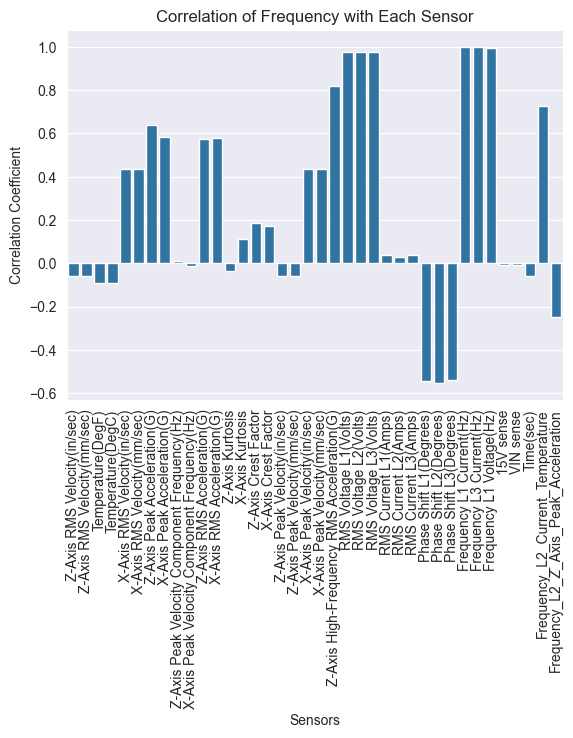

In [12]:
# correlation analysis for frequency
correlation_matrix_frequency = correlation_matrix['Frequency L2 Current']
correlation_matrix_frequency = correlation_matrix_frequency.drop('machine_state')
sns.barplot(x=correlation_matrix_frequency.drop('Frequency L2 Current').index, y=correlation_matrix_frequency.drop('Frequency L2 Current').values)
plt.title('Correlation of Frequency with Each Sensor')
plt.xlabel('Sensors')
plt.ylabel('Correlation Coefficient')
plt.xticks(rotation=90)  # Rotate labels for better readability
plt.show()

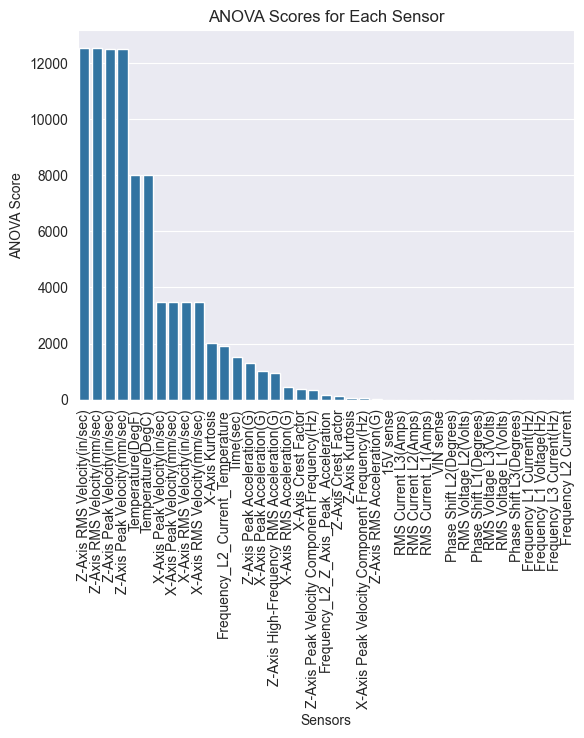

In [13]:
# ANOVA
selector = SelectKBest(f_classif, k='all')
selector.fit(X_scaled, y)
scores = selector.scores_

feature_scores = pd.DataFrame({
    'Feature': X.columns,
    'Score': scores
})

feature_scores = feature_scores.sort_values(by='Score', ascending=False)
sns.barplot(x=feature_scores['Feature'], y=feature_scores['Score'])
plt.title('ANOVA Scores for Each Sensor')
plt.xlabel('Sensors')
plt.ylabel('ANOVA Score')
plt.xticks(rotation=90)  # Rotate labels for better readability
plt.show()


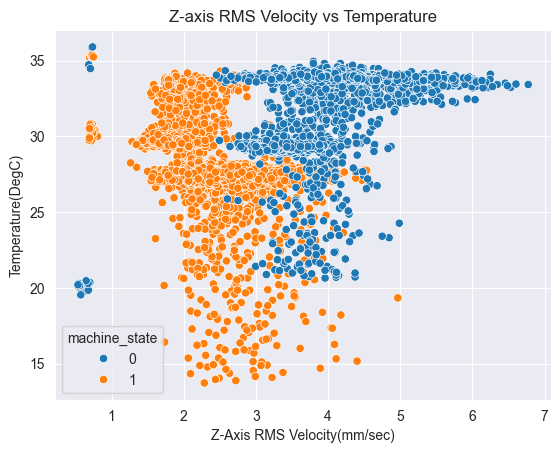

In [15]:
# plot features against themselves Z-axis rms velocity vs temperature linear regression
sns.lmplot(data=train_data, x='Z-Axis RMS Velocity(mm/s)', y='Temperature(DegC)', hue='machine_state')
plt.title('Z-Axis RMS Velocity vs Temperature')
plt.show()


